# Analisis exploratorio

Fragmentos por region anatomica, volumen fisico de cada fragmento, fragmento principal por hueso y graficas exploratorias del dataset completo.

- **Entradas:** `splits/dataset.csv` (`Dataset_splits`) y `data_mha/`.
- **Salidas:** `resultados/datos/fragmentos/metadata_fragments.csv` y `resultados/datos/fragmentos/main_fragments.csv` (esta ultima la usa Distancias_referencia).

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # modulos .py del proyecto

SPLITS_DIR = BASE_DIR / "splits"
from src.rutas import FRAGMENTOS_DIR

GENERATED_DATA_DIR = FRAGMENTOS_DIR      # resultados/datos/fragmentos
GENERATED_DATA_DIR.mkdir(parents=True, exist_ok=True)

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por Dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})

## 2. EDA de fragmentos por region anatomica

Se asigna cada label a una region anatomica aproximada: sacro, coxal izquierdo o coxal derecho. Luego se calcula el volumen fisico de cada fragmento usando el spacing en milimetros.

In [2]:
def label_to_region(label):
    if label == 0:
        return "background"
    if 1 <= label <= 10:
        return "sacro"
    if 11 <= label <= 20:
        return "coxal_izquierdo"
    if 21 <= label <= 30:
        return "coxal_derecho"
    return "desconocido"


fragment_rows = []

for _, row in df.iterrows():
    label_img = sitk.ReadImage(str(resolve_repo_path(row["label_path"])))
    label_vol = sitk.GetArrayFromImage(label_img)
    spacing = tuple(float(value) for value in label_img.GetSpacing())
    voxel_volume_mm3 = spacing[0] * spacing[1] * spacing[2]

    labels_present = np.unique(label_vol)
    labels_present = labels_present[labels_present != 0]

    for lab in labels_present:
        n_voxels = int(np.sum(label_vol == lab))
        fragment_rows.append({
            "case_id": row["case_id"],
            "label": int(lab),
            "region": label_to_region(int(lab)),
            "n_voxels": n_voxels,
            "volume_mm3": n_voxels * voxel_volume_mm3,
        })

frag_df = pd.DataFrame(fragment_rows)
frag_df.to_csv(GENERATED_DATA_DIR / "metadata_fragments.csv", index=False)
print(f"Total de fragmentos individuales en el dataset: {len(frag_df)}")
frag_df.head(10)

Total de fragmentos individuales en el dataset: 575


,case_id,label,region,n_voxels,volume_mm3
0,001,1,sacro,458539,223895.999430
1,001,11,coxal_izquierdo,762194,372165.044608
2,001,12,coxal_izquierdo,63957,31229.004372
3,001,21,coxal_derecho,844349,412279.791300
4,002,1,sacro,323928,176044.906041
5,002,2,sacro,39087,21242.582433
6,002,11,coxal_izquierdo,502549,273119.926299
7,002,21,coxal_derecho,470491,255697.389198
8,002,22,coxal_derecho,15260,8293.340700
9,002,23,coxal_derecho,19132,10397.653622


## 3. Resumen general del EDA

Se reporta el numero total de fragmentos y su distribucion por caso. Esto permite identificar si hay casos simples y casos mas complejos.

In [3]:
print("=== RESUMEN GENERAL ===")
print(f"Total de fragmentos (todas las regiones, todos los casos): {len(frag_df)}")
print(f"Fragmentos por caso -> min: {frag_df.groupby('case_id').size().min()}, "
      f"max: {frag_df.groupby('case_id').size().max()}, "
      f"media: {frag_df.groupby('case_id').size().mean():.2f}")

print("\n=== DISTRIBUCIÓN POR REGIÓN ANATÓMICA ===")
print(frag_df["region"].value_counts())

print("\n=== FRAGMENTOS POR REGIÓN, POR CASO (promedio) ===")
frag_por_region_caso = frag_df.groupby(["case_id", "region"]).size().reset_index(name="n_fragmentos")
print(frag_por_region_caso.groupby("region")["n_fragmentos"].describe())

=== RESUMEN GENERAL ===
Total de fragmentos (todas las regiones, todos los casos): 575
Fragmentos por caso -> min: 3, max: 9, media: 5.75

=== DISTRIBUCIÓN POR REGIÓN ANATÓMICA ===
region
coxal_izquierdo    215
coxal_derecho      207
sacro              153
Name: count, dtype: int64

=== FRAGMENTOS POR REGIÓN, POR CASO (promedio) ===
                 count  mean       std  min  25%  50%  75%  max
region                                                         
coxal_derecho    100.0  2.07  0.987344  1.0  1.0  2.0  3.0  4.0
coxal_izquierdo  100.0  2.15  1.067187  1.0  1.0  2.0  3.0  6.0
sacro            100.0  1.53  0.658357  1.0  1.0  1.0  2.0  4.0


## 4. Analisis de volumen de fragmentos

Se revisa la distribucion de volumenes en mm3. Los fragmentos muy pequenos pueden representar retos para segmentacion y metricas.

In [4]:
print("=== VOLUMEN DE FRAGMENTOS (mm³) ===")
print(frag_df["volume_mm3"].describe())

# Fragmentos sospechosamente pequeños (posible ruido de anotación vs. fragmento real)
umbral_pequeno = frag_df["volume_mm3"].quantile(0.05)  # percentil 5 más chico
pequenos = frag_df[frag_df["volume_mm3"] < umbral_pequeno]
print(f"\nFragmentos por debajo del percentil 5 de volumen (<{umbral_pequeno:.1f} mm³): {len(pequenos)}")
print(pequenos[["case_id", "region", "label", "volume_mm3"]].sort_values("volume_mm3").head(10))

=== VOLUMEN DE FRAGMENTOS (mm³) ===
count       575.000000
mean     135836.241955
std      114659.517155
min         282.212597
25%       23250.124644
50%      128182.935724
75%      234834.021490
max      416131.106541
Name: volume_mm3, dtype: float64

Fragmentos por debajo del percentil 5 de volumen (<3145.0 mm³): 29
    case_id           region  label   volume_mm3
299     052    coxal_derecho     23   282.212597
482     085            sacro      2   313.483475
215     038    coxal_derecho     23   518.747187
430     075  coxal_izquierdo     13   641.070251
329     057  coxal_izquierdo     13   683.141804
122     023  coxal_izquierdo     12   807.295788
478     084  coxal_izquierdo     14   812.787437
205     037            sacro      2   947.445813
477     084  coxal_izquierdo     13  1040.887642
312     054    coxal_derecho     24  1190.747253


## 5. Fragmento principal por hueso

Para cada caso y region, se identifica el fragmento de mayor volumen como fragmento principal. Los demas fragmentos se consideran conminutos para analisis posterior.

In [5]:
def get_main_fragment_per_bone(frag_df):
    rows = []
    for (case_id, region), group in frag_df.groupby(["case_id", "region"]):
        if region == "background":
            continue
        main_frag = group.loc[group["volume_mm3"].idxmax()]
        rows.append({
            "case_id": case_id,
            "region": region,
            "main_label": main_frag["label"],
            "main_volume_mm3": main_frag["volume_mm3"],
            "n_fragmentos_totales": len(group),
            "n_fragmentos_conminutos": len(group) - 1,
        })
    return pd.DataFrame(rows)

main_frag_df = get_main_fragment_per_bone(frag_df)
main_frag_df.to_csv(GENERATED_DATA_DIR / "main_fragments.csv", index=False)
main_frag_df.head(10)


,case_id,region,main_label,main_volume_mm3,n_fragmentos_totales,n_fragmentos_conminutos
0,001,coxal_derecho,21,412279.791300,1,0
1,001,coxal_izquierdo,11,372165.044608,2,1
2,001,sacro,1,223895.999430,1,0
3,002,coxal_derecho,21,255697.389198,3,2
4,002,coxal_izquierdo,11,273119.926299,1,0
5,002,sacro,1,176044.906041,2,1
6,003,coxal_derecho,21,281041.536819,1,0
7,003,coxal_izquierdo,11,236036.146324,4,3
8,003,sacro,1,181401.174675,1,0
9,004,coxal_derecho,21,214046.217773,2,1


## 6. Huesos fracturados y no fracturados por region

Se resume cuantos huesos tienen un solo fragmento y cuantos presentan multiples fragmentos por region anatomica.

In [6]:
print("=== HUESOS SIN FRACTURA (un solo fragmento) POR REGIÓN ===")
sin_fractura = main_frag_df[main_frag_df["n_fragmentos_totales"] == 1]
print(sin_fractura["region"].value_counts())

print("\n=== % de huesos fracturados por región ===")
total_por_region = main_frag_df["region"].value_counts()
fracturados_por_region = main_frag_df[main_frag_df["n_fragmentos_totales"] > 1]["region"].value_counts()
pct_fracturado = (fracturados_por_region / total_por_region * 100).round(1)
print(pct_fracturado)

=== HUESOS SIN FRACTURA (un solo fragmento) POR REGIÓN ===
region
sacro              55
coxal_derecho      36
coxal_izquierdo    34
Name: count, dtype: int64

=== % de huesos fracturados por región ===
region
coxal_derecho      64.0
coxal_izquierdo    66.0
sacro              45.0
Name: count, dtype: float64


## 7. Graficas exploratorias del EDA

Se generan graficas para visualizar fragmentos por caso, volumen por region y distribuciones generales del dataset.

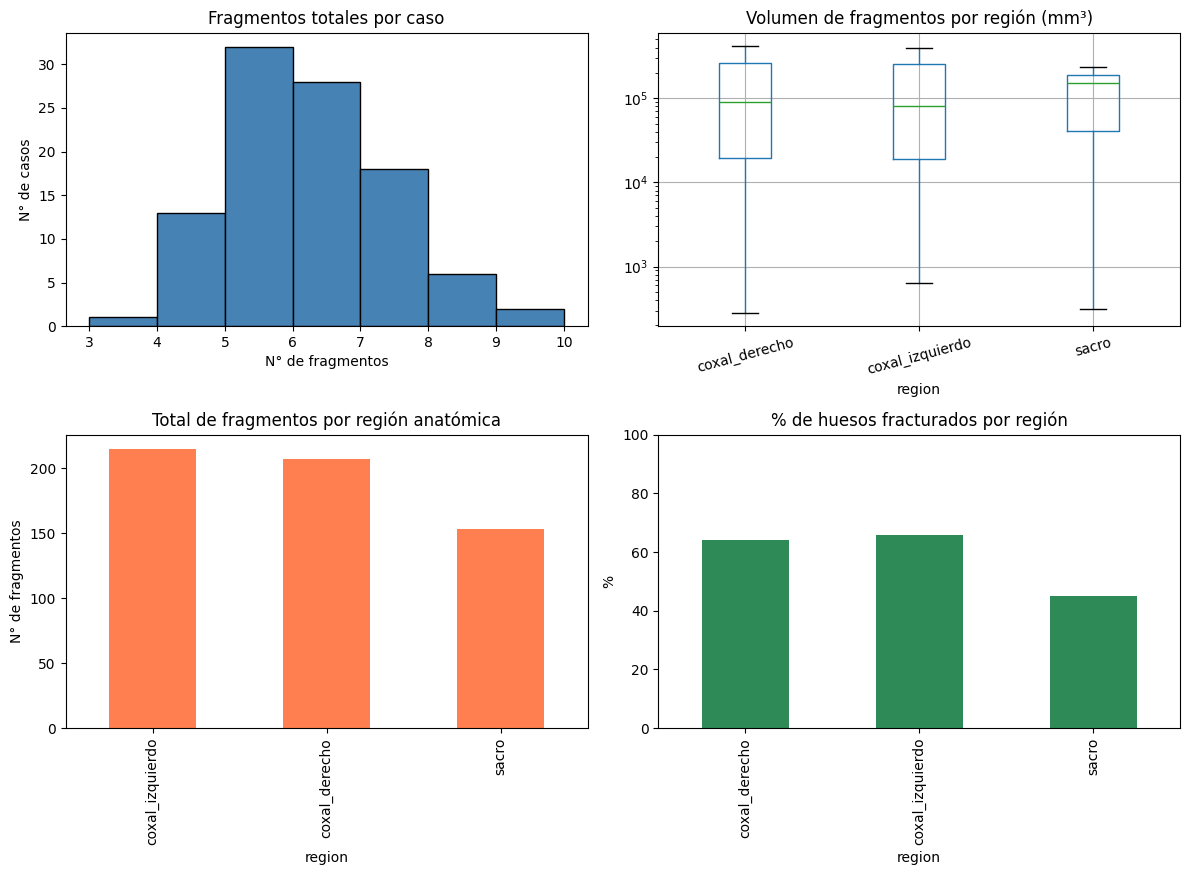

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Histograma: n° de fragmentos por caso (a nivel dataset completo)
frag_por_caso = frag_df.groupby("case_id").size()
axes[0, 0].hist(frag_por_caso, bins=range(frag_por_caso.min(), frag_por_caso.max() + 2), 
                 edgecolor="black", color="steelblue")
axes[0, 0].set_title("Fragmentos totales por caso")
axes[0, 0].set_xlabel("N° de fragmentos")
axes[0, 0].set_ylabel("N° de casos")

# Boxplot: volumen de fragmento por región
frag_df.boxplot(column="volume_mm3", by="region", ax=axes[0, 1])
axes[0, 1].set_title("Volumen de fragmentos por región (mm³)")
axes[0, 1].set_yscale("log")  # log porque probablemente hay outliers grandes
plt.sca(axes[0, 1])
plt.xticks(rotation=15)

# Barras: cantidad de fragmentos por región (total dataset)
frag_df["region"].value_counts().plot(kind="bar", ax=axes[1, 0], color="coral")
axes[1, 0].set_title("Total de fragmentos por región anatómica")
axes[1, 0].set_ylabel("N° de fragmentos")

# Barras: % de huesos fracturados por región
pct_fracturado.plot(kind="bar", ax=axes[1, 1], color="seagreen")
axes[1, 1].set_title("% de huesos fracturados por región")
axes[1, 1].set_ylabel("%")
axes[1, 1].set_ylim(0, 100)

plt.suptitle("")  # quita el título automático feo que pone pandas
plt.tight_layout()
plt.show()